# Task 2: Data Visualization with Matplotlib & Seaborn
**InternCircle Data Science Internship** | **Author:** Vignesh Murugesan

**Objective:** Create informative charts (bar charts, scatter plots, histograms, box plots, heatmap) with custom palettes and formatting, and use them to tell a story about who survived the Titanic.

## 1. Setup and data preparation

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

# Load the raw data and apply the same cleaning used in Task 1
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["Outcome"] = df["Survived"].map({0: "Did not survive", 1: "Survived"})
df["Class"] = df["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})
print(df.shape, "| missing values:", int(df.drop(columns="Cabin").isna().sum().sum()))

(891, 16) | missing values: 0


## 2. Custom style and colour palettes

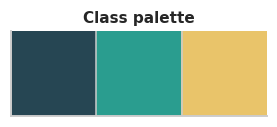

In [2]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PAL_OUTCOME = {"Did not survive": "#d1495b", "Survived": "#2a9d8f"}   # red / teal
PAL_SEX     = {"female": "#e76f9a", "male": "#3a86c8"}
PAL_CLASS   = ["#264653", "#2a9d8f", "#e9c46a"]
PAL_CLASS_D = dict(zip(["1st", "2nd", "3rd"], PAL_CLASS))

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

sns.palplot(PAL_CLASS)
plt.title("Class palette", fontsize=10)
plt.show()

## 3. Bar charts: who survived?

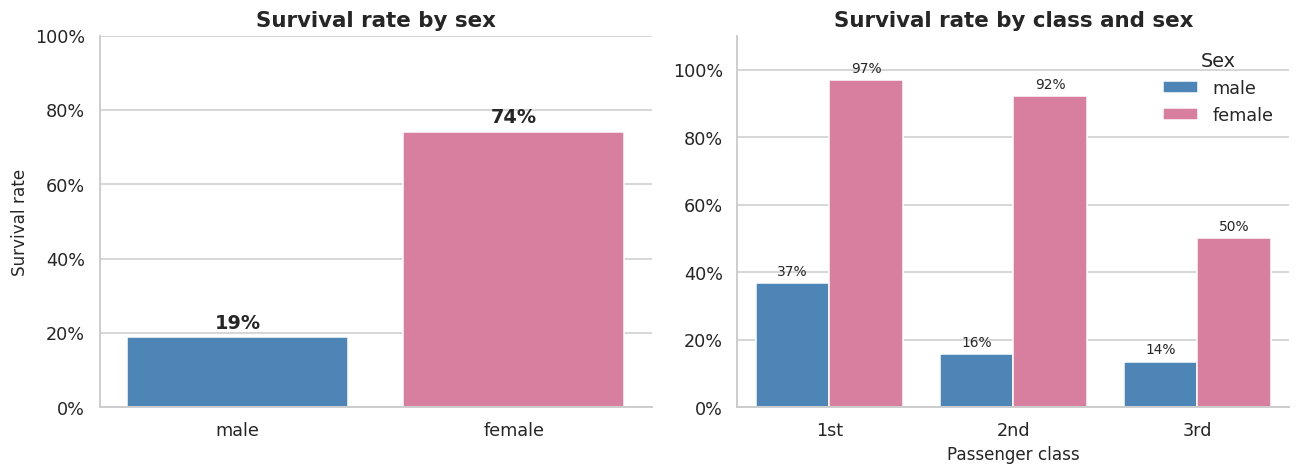

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Survival rate by sex with percentage labels
ax = sns.barplot(data=df, x="Sex", y="Survived", hue="Sex", palette=PAL_SEX, errorbar=None, legend=False, ax=axes[0])
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v.get_height():.0%}" for v in c], padding=3, fontweight="bold")
ax.set(title="Survival rate by sex", xlabel="", ylabel="Survival rate", ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

# (b) Survival rate by class, split by sex
ax = sns.barplot(data=df, x="Class", y="Survived", hue="Sex", palette=PAL_SEX, order=["1st", "2nd", "3rd"],
                 errorbar=None, ax=axes[1])
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v.get_height():.0%}" for v in c], padding=3, fontsize=9)
ax.set(title="Survival rate by class and sex", xlabel="Passenger class", ylabel="", ylim=(0, 1.1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(title="Sex", frameon=False)

save("01_bar_survival_sex_class")
plt.show()

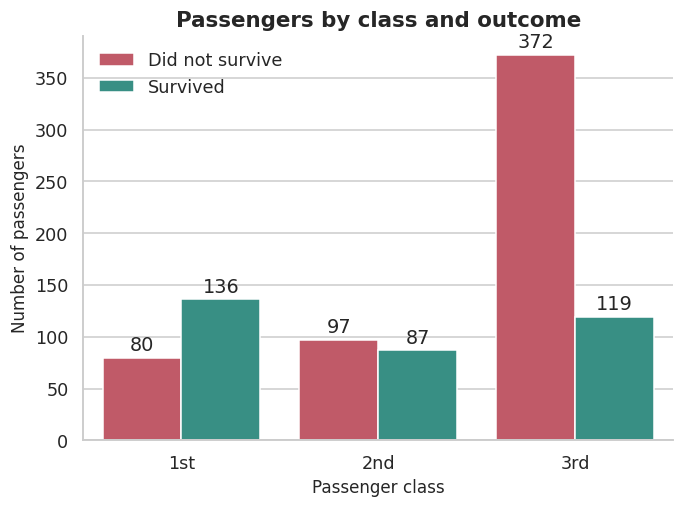

In [4]:
# Count of passengers by class and outcome (stacked view with countplot)
ax = sns.countplot(data=df, x="Class", hue="Outcome", order=["1st", "2nd", "3rd"], palette=PAL_OUTCOME)
for c in ax.containers:
    ax.bar_label(c, padding=2)
ax.set(title="Passengers by class and outcome", xlabel="Passenger class", ylabel="Number of passengers")
ax.legend(title="", frameon=False)
save("02_count_class_outcome")
plt.show()

## 4. Histograms: age and fare distributions

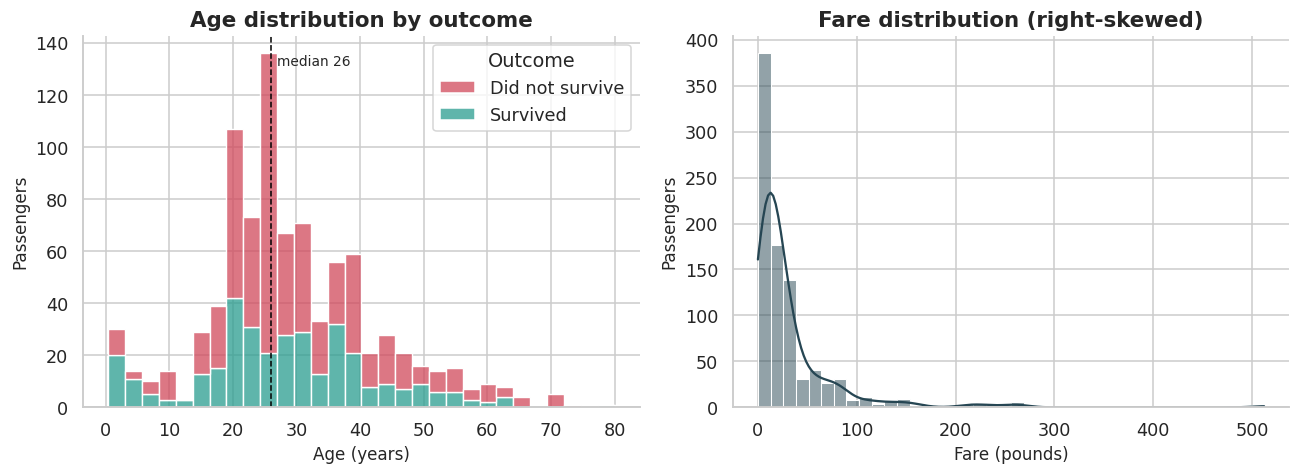

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=df, x="Age", hue="Outcome", palette=PAL_OUTCOME, bins=30, multiple="stack", edgecolor="white", ax=axes[0])
axes[0].axvline(df["Age"].median(), color="black", ls="--", lw=1)
axes[0].text(df["Age"].median() + 1, axes[0].get_ylim()[1] * 0.92, f"median {df['Age'].median():.0f}", fontsize=9)
axes[0].set(title="Age distribution by outcome", xlabel="Age (years)", ylabel="Passengers")

sns.histplot(data=df, x="Fare", bins=40, kde=True, color="#264653", edgecolor="white", ax=axes[1])
axes[1].set(title="Fare distribution (right-skewed)", xlabel="Fare (pounds)", ylabel="Passengers")

save("03_histograms_age_fare")
plt.show()

## 5. Box plots: spread and outliers

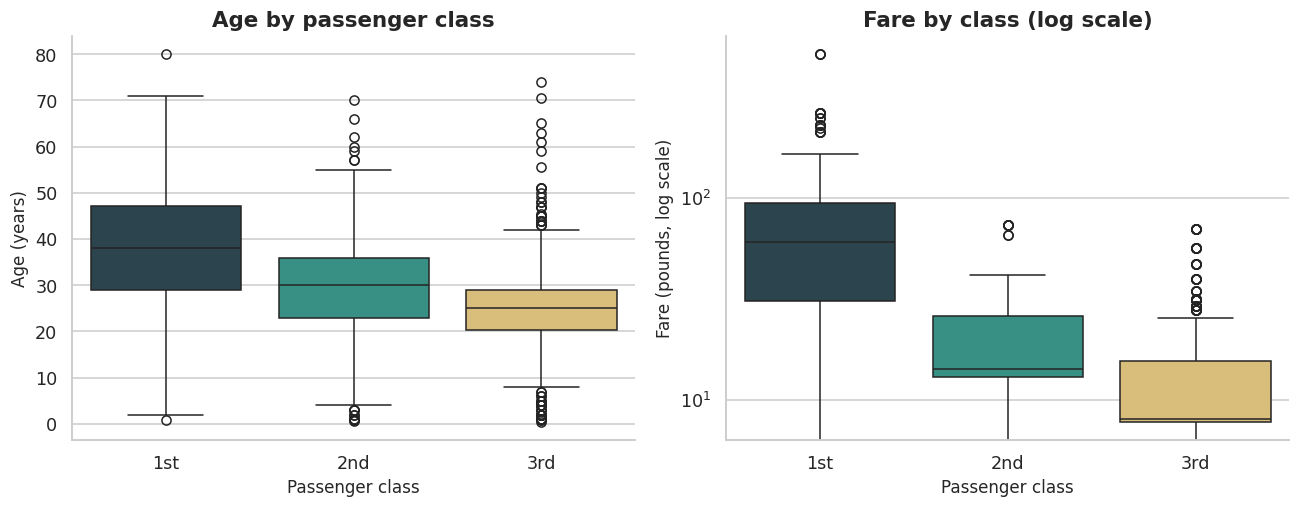

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.boxplot(data=df, x="Class", y="Age", hue="Class", order=["1st", "2nd", "3rd"], palette=PAL_CLASS_D, legend=False, ax=axes[0])
axes[0].set(title="Age by passenger class", xlabel="Passenger class", ylabel="Age (years)")

sns.boxplot(data=df, x="Class", y="Fare", hue="Class", order=["1st", "2nd", "3rd"], palette=PAL_CLASS_D, legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set(title="Fare by class (log scale)", xlabel="Passenger class", ylabel="Fare (pounds, log scale)")

save("04_boxplots_age_fare_by_class")
plt.show()

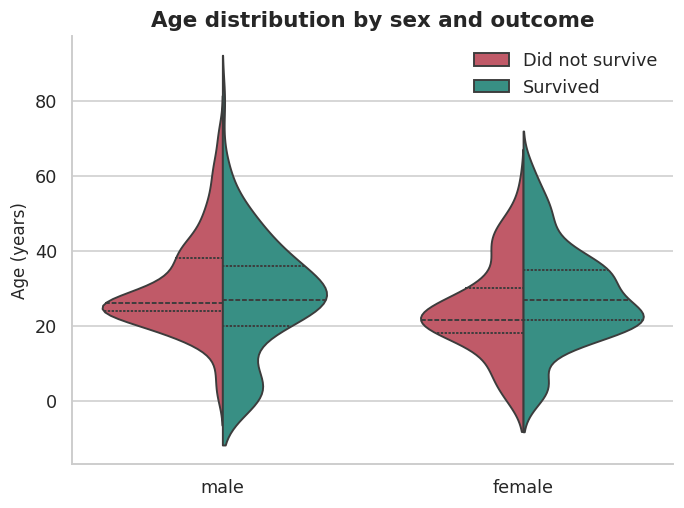

In [7]:
# Violin plot: age by sex and outcome
ax = sns.violinplot(data=df, x="Sex", y="Age", hue="Outcome", split=True, inner="quart", palette=PAL_OUTCOME)
ax.set(title="Age distribution by sex and outcome", xlabel="", ylabel="Age (years)")
ax.legend(title="", frameon=False, loc="upper right")
save("05_violin_age_sex_outcome")
plt.show()

## 6. Scatter plots: relationships

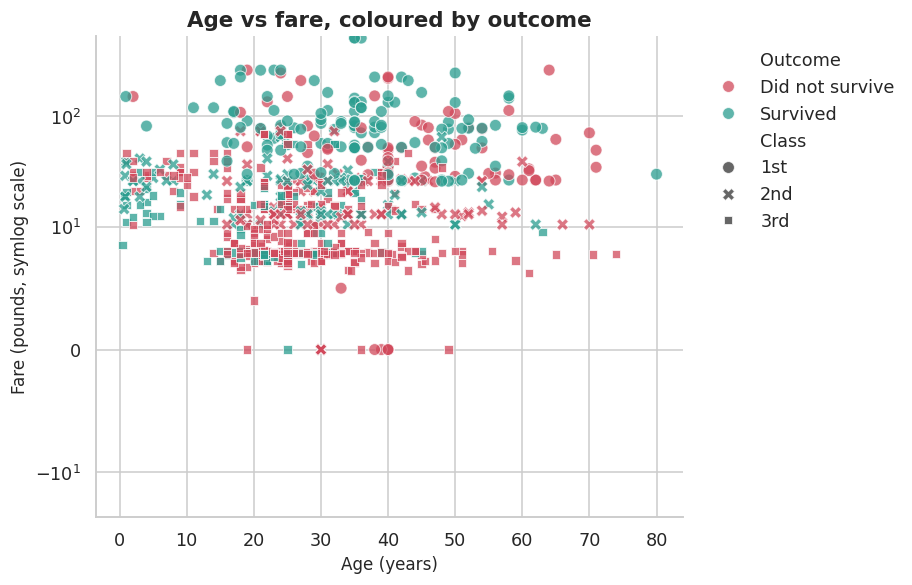

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Outcome", style="Class", style_order=["1st", "2nd", "3rd"],
                palette=PAL_OUTCOME, alpha=0.75, s=60, ax=ax)
ax.set_yscale("symlog", linthresh=10)
ax.set(title="Age vs fare, coloured by outcome", xlabel="Age (years)", ylabel="Fare (pounds, symlog scale)")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
save("06_scatter_age_fare")
plt.show()

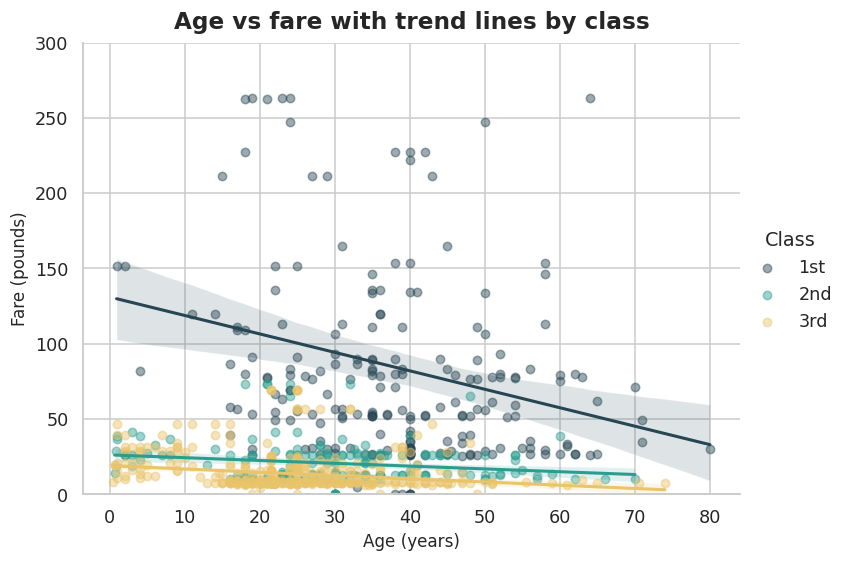

In [9]:
# Regression-style scatter: fare vs age for each class
g = sns.lmplot(data=df, x="Age", y="Fare", hue="Class", hue_order=["1st", "2nd", "3rd"], palette=PAL_CLASS,
               height=5, aspect=1.4, scatter_kws={"alpha": 0.45, "s": 30}, line_kws={"lw": 2})
g.set(ylim=(0, 300))
g.figure.suptitle("Age vs fare with trend lines by class", y=1.02, fontweight="bold")
g.set_axis_labels("Age (years)", "Fare (pounds)")
g.figure.savefig("figures/07_lmplot_age_fare_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Correlation matrix and heatmap

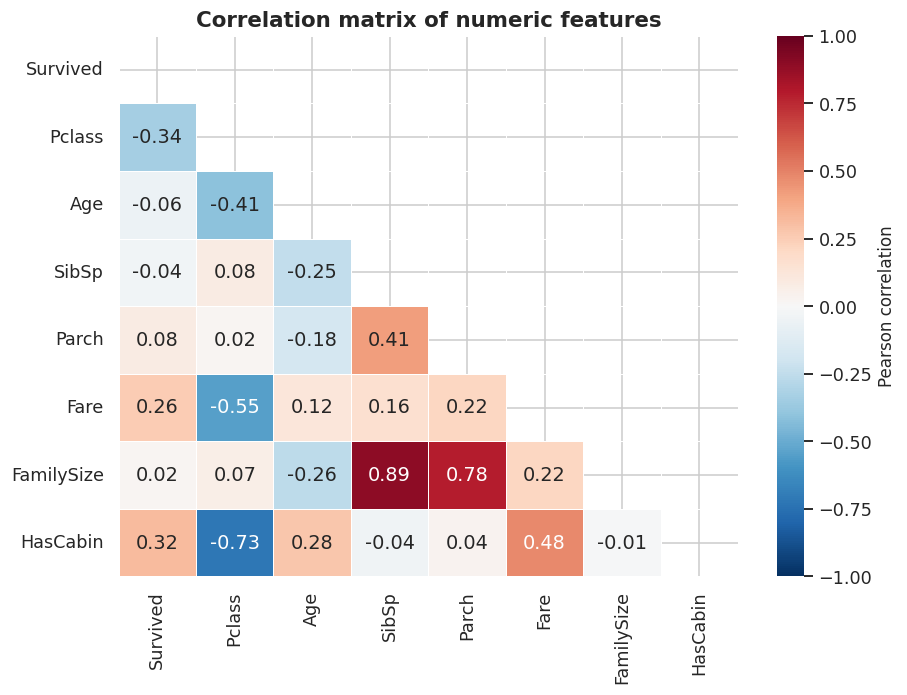

HasCabin      0.32
Fare          0.26
Parch         0.08
FamilySize    0.02
SibSp        -0.04
Age          -0.06
Pclass       -0.34
Name: Survived, dtype: float64

In [10]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper triangle

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation matrix of numeric features")
save("08_correlation_heatmap")
plt.show()

corr["Survived"].drop("Survived").sort_values(ascending=False).round(2)

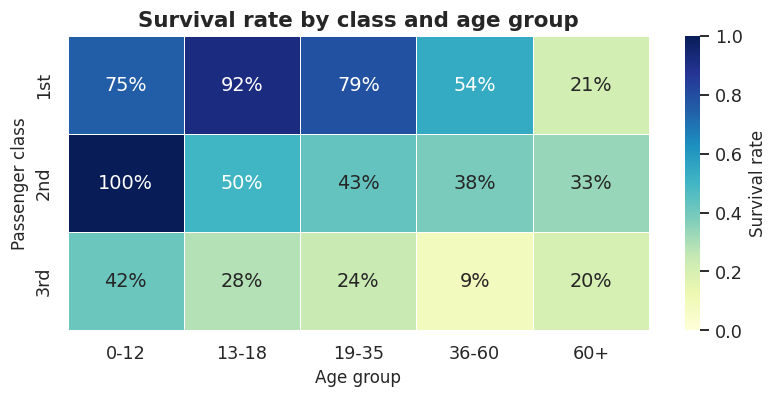

In [11]:
# Heatmap of survival rate: class x age group
age_group = pd.cut(df["Age"], [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
pivot = df.pivot_table(values="Survived", index="Class", columns=age_group, aggfunc="mean", observed=True).reindex(["1st", "2nd", "3rd"])

plt.figure(figsize=(7.5, 3.8))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "Survival rate"})
plt.title("Survival rate by class and age group")
plt.xlabel("Age group"); plt.ylabel("Passenger class")
save("09_heatmap_class_age_survival")
plt.show()

## 8. Summary dashboard

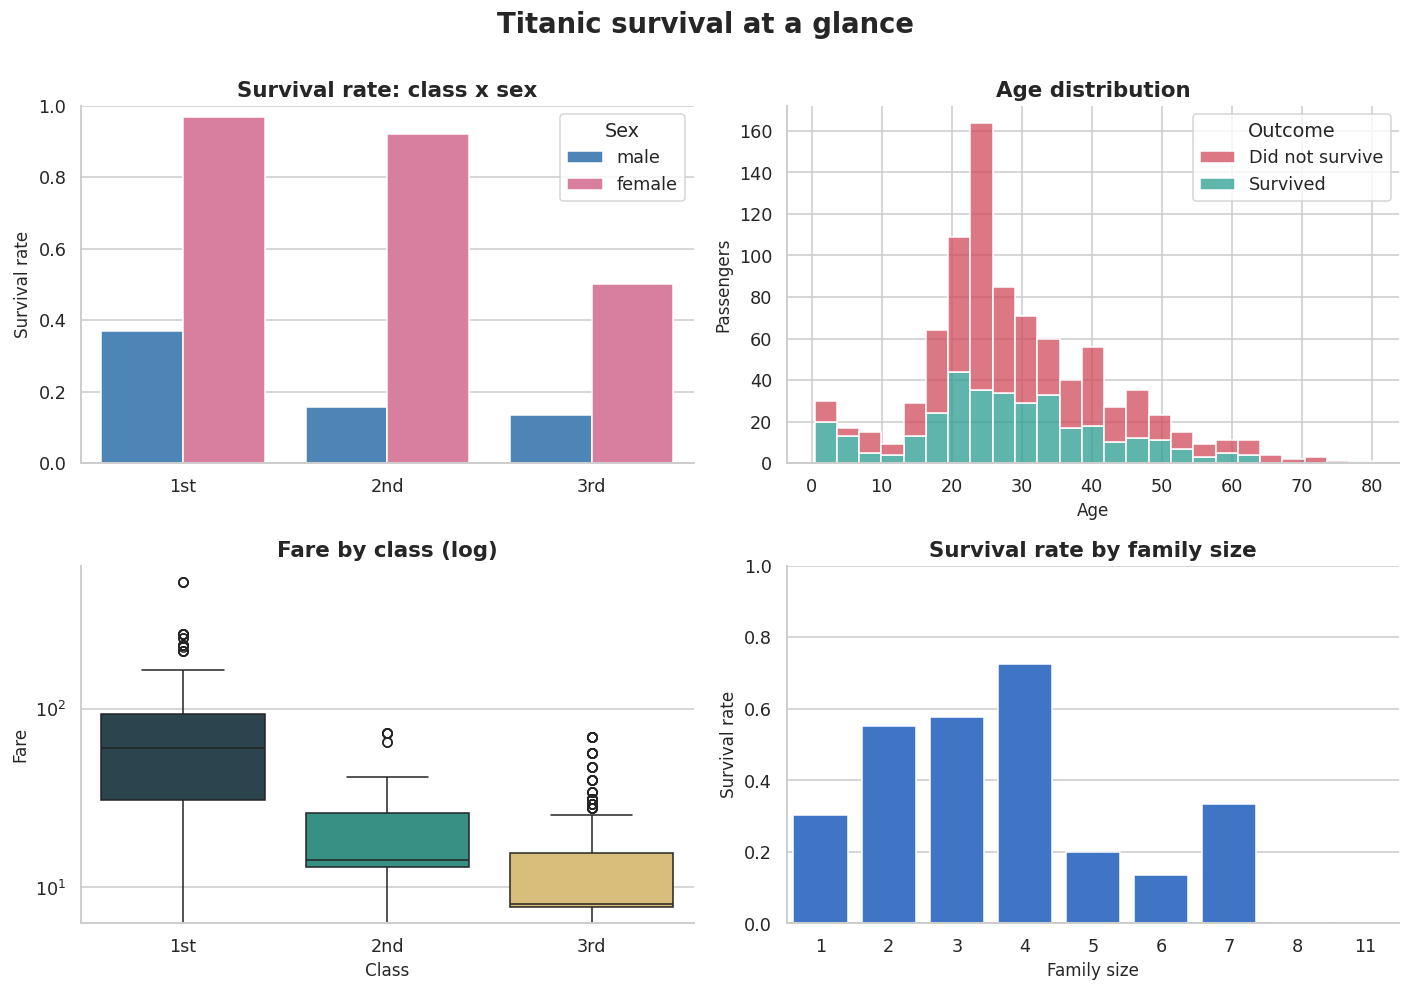

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Titanic survival at a glance", fontsize=18, fontweight="bold", y=1.0)

sns.barplot(data=df, x="Class", y="Survived", hue="Sex", palette=PAL_SEX, order=["1st", "2nd", "3rd"], errorbar=None, ax=axes[0, 0])
axes[0, 0].set(title="Survival rate: class x sex", xlabel="", ylabel="Survival rate", ylim=(0, 1))

sns.histplot(data=df, x="Age", hue="Outcome", palette=PAL_OUTCOME, bins=25, multiple="stack", edgecolor="white", ax=axes[0, 1])
axes[0, 1].set(title="Age distribution", xlabel="Age", ylabel="Passengers")

sns.boxplot(data=df, x="Class", y="Fare", hue="Class", order=["1st", "2nd", "3rd"], palette=PAL_CLASS_D, legend=False, ax=axes[1, 0])
axes[1, 0].set_yscale("log"); axes[1, 0].set(title="Fare by class (log)", xlabel="Class", ylabel="Fare")

sns.barplot(data=df, x="FamilySize", y="Survived", color="#2a6fdb", errorbar=None, ax=axes[1, 1])
axes[1, 1].set(title="Survival rate by family size", xlabel="Family size", ylabel="Survival rate", ylim=(0, 1))

save("10_dashboard")
plt.show()

## 9. Story told by the data

1. **Women and first-class passengers had the best odds.** Survival was about 74% for women and 19% for men, and about 63% for 1st class versus 24% for 3rd class (charts 1 and 2).
2. **The class gap exists for both sexes, but it is huge for women.** Nearly all 1st- and 2nd-class women survived, while 3rd-class women survived about half the time and 3rd-class men only about 14% (bar chart, heatmap 9).
3. **Children were prioritised.** The age histogram and heatmap show higher survival for passengers under 13, and lower survival for seniors (charts 3 and 9).
4. **Money tracked class.** Fare is strongly right-skewed with extreme outliers in 1st class, and fare correlates with class at about -0.55 (charts 3, 4 and 8).
5. **Fare and class are the numeric features most linked to survival** (correlation about +0.26 for fare and -0.34 for class), while age on its own is only weakly linked (chart 8).
6. **Travelling in a small family helped.** Survival peaks at family sizes 2-4 and drops for solo travellers and large families (dashboard).

**Visualization techniques used:** bar charts with labels, count plots, histograms with KDE, box plots (log scale), violin plot, scatter plot, regression plot, correlation heatmap with mask, pivot heatmap, subplot dashboard, custom palettes and formatted axes. All charts are saved in the `figures/` folder.